Cellule 1 : GPU, Drive, COLMAP, dépôt

In [2]:
import os
import torch

# 1. Vérifier le GPU
print("CUDA disponible :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))
else:
    print("ATTENTION : active le GPU dans Runtime > Change runtime type > T4 GPU")

# 2. Connecter Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 3. Installer COLMAP
!apt-get install -y -qq colmap
!colmap -h | head -n 2

# 4. Télécharger Gaussian Splatting
if not os.path.exists("/content/gaussian-splatting"):
    !git clone --recursive https://github.com/graphdeco-inria/gaussian-splatting.git /content/gaussian-splatting

# 5. Définir le chemin de la vidéo
VIDEO = "/content/drive/MyDrive/video_panda.MOV"

print("\nVidéo trouvée :", os.path.exists(VIDEO))

if os.path.exists(VIDEO):
    print("Taille :", round(os.path.getsize(VIDEO)/(1024*1024), 2), "MB")

CUDA disponible : True
GPU : Tesla T4
Mounted at /content/drive
Extracting templates from packages: 100%
Selecting previously unselected package libevdev2:amd64.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../00-libevdev2_1.13.1+dfsg-1build1_amd64.deb ...
Unpacking libevdev2:amd64 (1.13.1+dfsg-1build1) ...
Selecting previously unselected package at-spi2-common.
Preparing to unpack .../01-at-spi2-common_2.52.0-1build1_all.deb ...
Unpacking at-spi2-common (2.52.0-1build1) ...
Selecting previously unselected package libatspi2.0-0t64:amd64.
Preparing to unpack .../02-libatspi2.0-0t64_2.52.0-1build1_amd64.deb ...
Unpacking libatspi2.0-0t64:amd64 (2.52.0-1build1) ...
Selecting previously unselected package libxtst6:amd64.
Preparing to unpack .../03-libxtst6_2%3a1.2.3-1.1ubuntu0.1_amd64.deb ...
Unpacking libxtst6:amd64 (2:1.2.3-1.1ubuntu0.1) ...
Selecting previously unselected package session-migration.
Preparing to unpack .../04-session-migra

Cellule 2 : compilation CUDA (3 à 6 min)

In [4]:
from pathlib import Path
h = Path("/content/gaussian-splatting/submodules/diff-gaussian-rasterization/cuda_rasterizer/rasterizer_impl.h")
t = h.read_text()
if "#include <cstdint>" not in t:
    h.write_text("#include <cstdint>\n#include <cstddef>\n#include <stdint.h>\n" + t)
%cd /content/gaussian-splatting
!pip install --no-build-isolation --no-cache-dir ./submodules/diff-gaussian-rasterization 2>&1 | tail -n 2
!pip install --no-build-isolation --no-cache-dir ./submodules/simple-knn 2>&1 | tail -n 2
!pip install -q plyfile lpips
import diff_gaussian_rasterization, simple_knn
print("OK")

/content/gaussian-splatting
OK


Cellule 3 : extraire les images de la vidéo

In [5]:
import glob, shutil, cv2, numpy as np
from PIL import Image
shutil.rmtree("/content/frames", ignore_errors=True); os.makedirs("/content/frames")
!ffmpeg -loglevel error -y -i "{VIDEO}" -vf "fps=3,scale=720:-2" -qscale:v 2 /content/frames/f_%04d.jpg

files = sorted(glob.glob("/content/frames/*.jpg"))
score = [cv2.Laplacian(cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2GRAY), cv2.CV_64F).var() for f in files]
keep = [f for f, s in zip(files, score) if s >= np.percentile(score, 15)]   # on retire les 15 % les plus flous
MAX = 90
if len(keep) > MAX:
    keep = [keep[i] for i in np.linspace(0, len(keep) - 1, MAX).astype(int)]
shutil.rmtree("/content/scene3", ignore_errors=True); os.makedirs("/content/scene3/input")
for i, f in enumerate(keep):
    shutil.copy(f, f"/content/scene3/input/img_{i:03d}.jpg")
print(len(files), "images extraites ->", len(keep), "gardées")
print("Taille d'une image (largeur, hauteur) :", Image.open("/content/scene3/input/img_000.jpg").size)

154 images extraites -> 90 gardées
Taille d'une image (largeur, hauteur) : (720, 960)


Cellule 4 : COLMAP, extraction des points (environ 3 min)

In [6]:
!mkdir -p /content/scene3/distorted/sparse
!colmap feature_extractor --database_path /content/scene3/distorted/database.db --image_path /content/scene3/input --ImageReader.single_camera 1 --ImageReader.camera_model SIMPLE_RADIAL --SiftExtraction.use_gpu 0 --SiftExtraction.max_num_features 4000 2>&1 | tail -n 3

I20261127 11:40:17.776786  4370 feature_extraction.cc:289]   Focal Length:    1152.00px
I20261127 11:40:17.776804  4370 feature_extraction.cc:302]   Features:        6879
I20261127 11:40:17.793411  4365 timer.cc:91] Elapsed time: 2.044 [minutes]


Cellule 5 : COLMAP, appariement (15 à 25 min, la plus longue)

In [8]:
!colmap exhaustive_matcher --database_path /content/scene3/distorted/database.db --SiftMatching.use_gpu 0 2>&1 | tail -n 3

I20261127 12:14:50.728475  6817 feature_matching.cc:231] Matching block [2/2, 2/2]
I20261127 12:21:55.387116  6817 feature_matching.cc:46]  in 424.659s
I20261127 12:21:55.431680  6817 timer.cc:91] Elapsed time: 34.152 [minutes]


Cellule 6 : COLMAP, poses de caméras et point de contrôle

In [10]:
!colmap mapper --database_path /content/scene3/distorted/database.db --image_path /content/scene3/input --output_path /content/scene3/distorted/sparse 2>&1 | tail -n 3
print("Sous-dossiers de sparse :")
!ls /content/scene3/distorted/sparse
!colmap model_analyzer --path /content/scene3/distorted/sparse/0 2>&1 | grep -E "Cameras|Registered|Points:|reprojection"

I20261127 12:28:02.903291 15795 incremental_mapper.cc:119] => Changed observations: 0.000065
I20261127 12:28:02.903335 15795 incremental_mapper.cc:167] => Filtered images: 0
I20261127 12:28:02.968703 15795 timer.cc:91] Elapsed time: 5.879 [minutes]
Sous-dossiers de sparse :
0
I20261127 12:28:03.353929 17669 model.cc:429] Cameras: 1
I20261127 12:28:03.354104 17669 model.cc:431] Registered images: 90
I20261127 12:28:03.354112 17669 model.cc:433] Points: 33720
I20261127 12:28:03.354169 17669 model.cc:441] Mean reprojection error: 0.450981px


Cellule 7 : conversion pour le Gaussian Splatting et sauvegarde

In [11]:
!cd /content/gaussian-splatting && python convert.py -s /content/scene3 --no_gpu --skip_matching 2>&1 | tail -n 2
!ls /content/scene3/images | wc -l
!ls /content/scene3/sparse/0
!cp -r /content/scene3 /content/drive/MyDrive/scene_gs_v3
print("Scène sauvegardée sur Drive")

I20261127 12:28:50.663932 17830 timer.cc:91] Elapsed time: 0.200 [minutes]
Done.
90
cameras.bin  images.bin  points3D.bin
Scène sauvegardée sur Drive


Cellule 8 : diagnostic des caméras

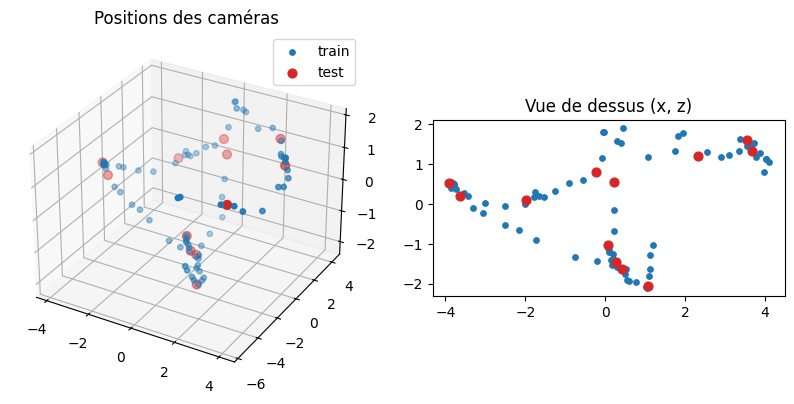

Angle jusqu'à la vue d'entraînement la plus proche (test) : [np.float64(0.2), np.float64(0.1), np.float64(1.3), np.float64(0.7), np.float64(2.5), np.float64(2.4), np.float64(2.3), np.float64(1.2), np.float64(2.1), np.float64(0.8), np.float64(0.9), np.float64(5.1)]


In [12]:
import sys, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, "/content/gaussian-splatting")
from scene.colmap_loader import read_extrinsics_binary, qvec2rotmat

ext = read_extrinsics_binary("/content/scene3/sparse/0/images.bin")
items = sorted(ext.values(), key=lambda im: im.name)
C, D, names = [], [], []
for im in items:
    R = qvec2rotmat(im.qvec)
    C.append(-R.T @ im.tvec); D.append(R.T @ np.array([0, 0, 1.0])); names.append(im.name)
C, D = np.array(C), np.array(D)
test = np.array([i % 8 == 0 for i in range(len(items))])

fig = plt.figure(figsize=(10, 5))
ax = fig.add_subplot(121, projection="3d")
ax.scatter(*C[~test].T, c="tab:blue", s=15, label="train")
ax.scatter(*C[test].T, c="tab:red", s=40, label="test"); ax.legend(); ax.set_title("Positions des caméras")
ax2 = fig.add_subplot(122)
ax2.scatter(C[~test, 0], C[~test, 2], c="tab:blue", s=15); ax2.scatter(C[test, 0], C[test, 2], c="tab:red", s=40)
ax2.set_aspect("equal"); ax2.set_title("Vue de dessus (x, z)")
plt.show()

angles = []
for i in np.where(test)[0]:
    cos = (D[~test] @ D[i]).max()
    angles.append(np.degrees(np.arccos(np.clip(cos, -1, 1))))
print("Angle jusqu'à la vue d'entraînement la plus proche (test) :", [round(a, 1) for a in angles])

Cellule 9 : entraînement de validation (7 000 itérations, environ 10 min)

In [13]:
import time; t0 = time.time()
!cd /content/gaussian-splatting && python train.py -s /content/scene3 -m /content/output/panda_v3 --eval --iterations 7000 --test_iterations 7000 --save_iterations 7000 2>&1 | tail -n 8
print("Temps d'entraînement (s) :", round(time.time() - t0))
!cp -r /content/output/panda_v3 /content/drive/MyDrive/panda_gs_v3


[ITER 7000] Evaluating test: L1 0.01634794636629522 PSNR 32.645119190216064 [27/11 12:37:07]

[ITER 7000] Evaluating train: L1 0.018855766579508784 PSNR 32.84227676391602 [27/11 12:37:11]

[ITER 7000] Saving Gaussians [27/11 12:37:11]

Training complete. [27/11 12:37:14]
Temps d'entraînement (s) : 448


Cellule 10 : rendu, métriques et figure

Loading Test Cameras [27/11 12:37:28]
Rendering progress: 100%|██████████| 12/12 [00:07<00:00,  1.66it/s]
100%|██████████| 7.12k/7.12k [00:00<00:00, 21.8MB/s]
Metric evaluation progress: 100%|██████████| 12/12 [00:28<00:00,  2.34s/it]
  SSIM :    0.9595542
  PSNR :   32.6165123
  LPIPS:    0.0878406



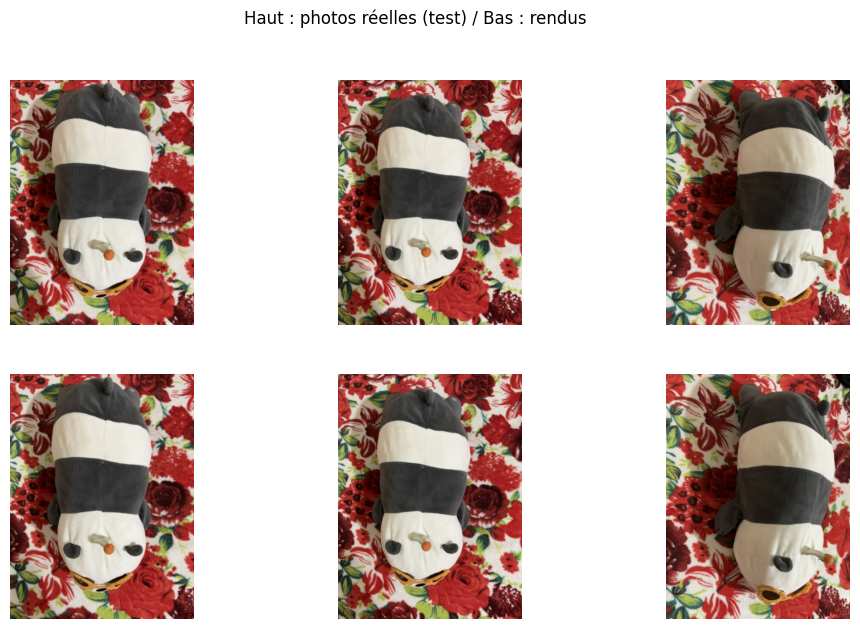

In [14]:
!cd /content/gaussian-splatting && python render.py -m /content/output/panda_v3 --iteration 7000 --skip_train 2>&1 | tail -n 2
!cd /content/gaussian-splatting && python metrics.py -m /content/output/panda_v3 2>&1 | tail -n 6
import glob
b = "/content/output/panda_v3/test/ours_7000"
R = sorted(glob.glob(f"{b}/renders/*.png"))[:3]; G = sorted(glob.glob(f"{b}/gt/*.png"))[:3]
fig, ax = plt.subplots(2, len(R), figsize=(4 * len(R), 7))
for i in range(len(R)):
    ax[0, i].imshow(Image.open(G[i])); ax[0, i].axis("off")
    ax[1, i].imshow(Image.open(R[i])); ax[1, i].axis("off")
fig.suptitle("Haut : photos réelles (test) / Bas : rendus")
plt.show()

Sauvegarder le modèle Gaussian Splatting

In [18]:
import os
import shutil

SOURCE = "/content/output/panda_v3"
DEST = "/content/drive/MyDrive/Projet6_3D/panda_gaussian_splatting"

assert os.path.exists(os.path.join(SOURCE, "point_cloud", "iteration_7000")), \
    "Modèle iteration_7000 introuvable !"

os.makedirs(os.path.dirname(DEST), exist_ok=True)

shutil.copytree(SOURCE, DEST, dirs_exist_ok=True)

print("Modèle sauvegardé avec succès !")
print("Destination :", DEST)

Modèle sauvegardé avec succès !
Destination : /content/drive/MyDrive/Projet6_3D/panda_gaussian_splatting


Sauvegarder COLMAP

In [19]:
SOURCE_COLMAP = "/content/scene3/distorted/sparse/0"
DEST_COLMAP = "/content/drive/MyDrive/Projet6_3D/COLMAP/sparse/0"

assert os.path.exists(SOURCE_COLMAP), "Reconstruction COLMAP introuvable !"

shutil.copytree(SOURCE_COLMAP, DEST_COLMAP, dirs_exist_ok=True)

print("Reconstruction COLMAP sauvegardée !")
print("Fichiers :", os.listdir(DEST_COLMAP))

Reconstruction COLMAP sauvegardée !
Fichiers : ['points3D.bin', 'project.ini', 'cameras.bin', 'images.bin']


Sauvegarder les métriques

In [20]:
metrics = """
PROJET 6 - RECONSTRUCTION 3D
Objet : Panda
Méthode : 3D Gaussian Splatting
Images enregistrées : 90
Points 3D COLMAP : 33720
Erreur moyenne de reprojection : 0.450981 px
Iterations : 7000
Temps d'entrainement : 448 secondes
PSNR Test : 32.6165123
SSIM : 0.9595542
LPIPS : 0.0878406
"""

metrics_path = "/content/drive/MyDrive/Projet6_3D/metriques_panda.txt"

with open(metrics_path, "w") as f:
    f.write(metrics)

print("Métriques sauvegardées :", metrics_path)

Métriques sauvegardées : /content/drive/MyDrive/Projet6_3D/metriques_panda.txt


Étape 4 — Réduction de la taille du modèle et mesure de la vitesse

Première étape : mesurer le modèle original

In [21]:
import os
from plyfile import PlyData

MODEL = "/content/drive/MyDrive/Projet6_3D/panda_gaussian_splatting"

PLY = os.path.join(
    MODEL,
    "point_cloud",
    "iteration_7000",
    "point_cloud.ply"
)

assert os.path.exists(PLY), f"Fichier introuvable : {PLY}"

ply = PlyData.read(PLY)

nb_gaussians = len(ply["vertex"].data)
taille_mb = os.path.getsize(PLY) / (1024 * 1024)

print("===== MODÈLE ORIGINAL =====")
print("Nombre de Gaussiennes :", nb_gaussians)
print("Taille du fichier PLY :", round(taille_mb, 2), "MB")
print("Chemin :", PLY)

===== MODÈLE ORIGINAL =====
Nombre de Gaussiennes : 384942
Taille du fichier PLY : 91.04 MB
Chemin : /content/drive/MyDrive/Projet6_3D/panda_gaussian_splatting/point_cloud/iteration_7000/point_cloud.ply


Mesurer la vitesse du modèle original

In [22]:
import os
import time
import subprocess

REPO = "/content/gaussian-splatting"
MODEL = "/content/drive/MyDrive/Projet6_3D/panda_gaussian_splatting"

assert os.path.exists(REPO), "Repository Gaussian Splatting introuvable"
assert os.path.exists(os.path.join(MODEL, "cfg_args")), "cfg_args introuvable"

start = time.time()

result = subprocess.run(
    [
        "python", "render.py",
        "-m", MODEL,
        "--iteration", "7000",
        "--skip_train"
    ],
    cwd=REPO,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT
)

elapsed = time.time() - start

print(result.stdout[-3000:])
print("\n===== BENCHMARK ORIGINAL =====")
print("Temps total :", round(elapsed, 2), "secondes")

if result.returncode != 0:
    print("Erreur pendant le rendu !")
else:
    print("Rendu terminé avec succès.")

    render_dir = os.path.join(
        MODEL, "test", "ours_7000", "renders"
    )

    if os.path.exists(render_dir):
        frames = [
            f for f in os.listdir(render_dir)
            if f.lower().endswith((".png", ".jpg"))
        ]

        print("Images rendues :", len(frames))

        if frames:
            print("Débit moyen approximatif :",
                  round(len(frames) / elapsed, 2), "images/s")

t iteration 7000 [27/11 12:47:55]
------------LLFF HOLD------------- [27/11 12:47:55]

Reading camera 1/90
Reading camera 2/90
Reading camera 3/90
Reading camera 4/90
Reading camera 5/90
Reading camera 6/90
Reading camera 7/90
Reading camera 8/90
Reading camera 9/90
Reading camera 10/90
Reading camera 11/90
Reading camera 12/90
Reading camera 13/90
Reading camera 14/90
Reading camera 15/90
Reading camera 16/90
Reading camera 17/90
Reading camera 18/90
Reading camera 19/90
Reading camera 20/90
Reading camera 21/90
Reading camera 22/90
Reading camera 23/90
Reading camera 24/90
Reading camera 25/90
Reading camera 26/90
Reading camera 27/90
Reading camera 28/90
Reading camera 29/90
Reading camera 30/90
Reading camera 31/90
Reading camera 32/90
Reading camera 33/90
Reading camera 34/90
Reading camera 35/90
Reading camera 36/90
Reading camera 37/90
Reading camera 38/90
Reading camera 39/90
Reading camera 40/90
Reading camera 41/90
Reading camera 42/90
Reading camera 43/90
Reading camera 44/9

analyser les opacités

In [23]:
import numpy as np
from plyfile import PlyData

PLY_PATH = "/content/drive/MyDrive/Projet6_3D/panda_gaussian_splatting/point_cloud/iteration_7000/point_cloud.ply"

plydata = PlyData.read(PLY_PATH)
vertices = plydata["vertex"].data

# Les opacités sont stockées sous forme de logits
opacity_logits = np.asarray(vertices["opacity"])

# Conversion en probabilités entre 0 et 1
opacities = 1 / (1 + np.exp(-opacity_logits))

print("===== ANALYSE DES OPACITÉS =====")
print("Nombre de Gaussiennes :", len(opacities))
print("Opacité minimale :", round(float(opacities.min()), 6))
print("Opacité maximale :", round(float(opacities.max()), 6))
print("Opacité moyenne :", round(float(opacities.mean()), 6))
print("\nPercentiles :")

for p in [1, 5, 10, 25, 50, 75, 90]:
    print(f"{p}% :", round(float(np.percentile(opacities, p)), 6))

print("\n===== GAUSSIENNES CONSERVÉES SELON LE SEUIL =====")

for seuil in [0.001, 0.005, 0.01, 0.02, 0.05]:
    conservées = np.sum(opacities >= seuil)
    supprimées = len(opacities) - conservées
    print(
        f"Seuil {seuil}: "
        f"{conservées} conservées | "
        f"{supprimées} supprimées | "
        f"{100 * supprimées / len(opacities):.2f}% supprimées"
    )

===== ANALYSE DES OPACITÉS =====
Nombre de Gaussiennes : 384942
Opacité minimale : 0.003886
Opacité maximale : 0.993095
Opacité moyenne : 0.17622

Percentiles :
1% : 0.01
5% : 0.029232
10% : 0.042555
25% : 0.071437
50% : 0.12778
75% : 0.233081
90% : 0.383985

===== GAUSSIENNES CONSERVÉES SELON LE SEUIL =====
Seuil 0.001: 384942 conservées | 0 supprimées | 0.00% supprimées
Seuil 0.005: 384911 conservées | 31 supprimées | 0.01% supprimées
Seuil 0.01: 380705 conservées | 4237 supprimées | 1.10% supprimées
Seuil 0.02: 374537 conservées | 10405 supprimées | 2.70% supprimées
Seuil 0.05: 332690 conservées | 52252 supprimées | 13.57% supprimées


Créer le modèle optimisé

In [24]:
import os
import shutil
import numpy as np
from plyfile import PlyData

# Chemins
ORIGINAL = "/content/drive/MyDrive/Projet6_3D/panda_gaussian_splatting"
OPTIMIZED = "/content/output/panda_optimized"

# Copier le modèle original
if os.path.exists(OPTIMIZED):
    shutil.rmtree(OPTIMIZED)

shutil.copytree(ORIGINAL, OPTIMIZED)

# Charger le PLY de la copie
ply_path = os.path.join(
    OPTIMIZED,
    "point_cloud",
    "iteration_7000",
    "point_cloud.ply"
)

plydata = PlyData.read(ply_path)
vertices = plydata["vertex"].data

# Calculer les opacités réelles
opacity_logits = np.asarray(vertices["opacity"])
opacities = 1 / (1 + np.exp(-opacity_logits))

# Appliquer le seuil
seuil = 0.05
mask = opacities >= seuil

# Conserver les Gaussiennes sélectionnées
vertices_optimized = vertices[mask]
plydata["vertex"].data = vertices_optimized

# Enregistrer le nouveau PLY
plydata.write(ply_path)

# Comparaison
taille_originale = os.path.getsize(
    os.path.join(
        ORIGINAL, "point_cloud", "iteration_7000", "point_cloud.ply"
    )
) / (1024 ** 2)

taille_optimisee = os.path.getsize(ply_path) / (1024 ** 2)

print("===== OPTIMISATION TERMINÉE =====")
print("Gaussiennes originales :", len(vertices))
print("Gaussiennes conservées :", len(vertices_optimized))
print("Gaussiennes supprimées :", len(vertices) - len(vertices_optimized))
print("Taille originale :", round(taille_originale, 2), "MB")
print("Taille optimisée :", round(taille_optimisee, 2), "MB")
print("Réduction :", round(
    (1 - taille_optimisee / taille_originale) * 100, 2
), "%")
print("Modèle original préservé :", os.path.exists(
    os.path.join(ORIGINAL, "point_cloud", "iteration_7000", "point_cloud.ply")
))

===== OPTIMISATION TERMINÉE =====
Gaussiennes originales : 384942
Gaussiennes conservées : 332690
Gaussiennes supprimées : 52252
Taille originale : 91.04 MB
Taille optimisée : 78.69 MB
Réduction : 13.57 %
Modèle original préservé : True


Tester le rendu optimisé

In [25]:
import os
import time
import subprocess

REPO = "/content/gaussian-splatting"
MODEL = "/content/output/panda_optimized"

start = time.time()

result = subprocess.run(
    [
        "python", "render.py",
        "-m", MODEL,
        "--iteration", "7000",
        "--skip_train"
    ],
    cwd=REPO,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT
)

elapsed = time.time() - start

print(result.stdout[-3000:])

print("\n===== BENCHMARK MODÈLE OPTIMISÉ =====")
print("Temps total :", round(elapsed, 2), "secondes")

if result.returncode == 0:
    render_dir = os.path.join(
        MODEL, "test", "ours_7000", "renders"
    )

    frames = [
        f for f in os.listdir(render_dir)
        if f.lower().endswith((".png", ".jpg"))
    ]

    print("Images rendues :", len(frames))
    print("Débit moyen :", round(len(frames) / elapsed, 2), "images/s")
    print("Rendu terminé avec succès.")
else:
    print("Erreur pendant le rendu.")

t iteration 7000 [27/11 12:50:01]
------------LLFF HOLD------------- [27/11 12:50:01]

Reading camera 1/90
Reading camera 2/90
Reading camera 3/90
Reading camera 4/90
Reading camera 5/90
Reading camera 6/90
Reading camera 7/90
Reading camera 8/90
Reading camera 9/90
Reading camera 10/90
Reading camera 11/90
Reading camera 12/90
Reading camera 13/90
Reading camera 14/90
Reading camera 15/90
Reading camera 16/90
Reading camera 17/90
Reading camera 18/90
Reading camera 19/90
Reading camera 20/90
Reading camera 21/90
Reading camera 22/90
Reading camera 23/90
Reading camera 24/90
Reading camera 25/90
Reading camera 26/90
Reading camera 27/90
Reading camera 28/90
Reading camera 29/90
Reading camera 30/90
Reading camera 31/90
Reading camera 32/90
Reading camera 33/90
Reading camera 34/90
Reading camera 35/90
Reading camera 36/90
Reading camera 37/90
Reading camera 38/90
Reading camera 39/90
Reading camera 40/90
Reading camera 41/90
Reading camera 42/90
Reading camera 43/90
Reading camera 44/9

comparer la qualité

In [26]:
import os
import subprocess

REPO = "/content/gaussian-splatting"

models = {
    "Original": "/content/drive/MyDrive/Projet6_3D/panda_gaussian_splatting",
    "Optimisé": "/content/output/panda_optimized"
}

for nom, modele in models.items():
    print(f"\n===== ÉVALUATION : {nom} =====")

    result = subprocess.run(
        [
            "python", "metrics.py",
            "-m", modele
        ],
        cwd=REPO,
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT
    )

    print(result.stdout[-2500:])

    if result.returncode != 0:
        print("Erreur pendant l'évaluation.")


===== ÉVALUATION : Original =====

Scene: /content/drive/MyDrive/Projet6_3D/panda_gaussian_splatting
Method: ours_7000

Metric evaluation progress: 100%|██████████| 12/12 [00:20<00:00,  1.71s/it]
  SSIM :    0.9595542
  PSNR :   32.6165123
  LPIPS:    0.0878406



===== ÉVALUATION : Optimisé =====

Scene: /content/output/panda_optimized
Method: ours_7000

Metric evaluation progress: 100%|██████████| 12/12 [00:21<00:00,  1.78s/it]
  SSIM :    0.9569139
  PSNR :   31.5311966
  LPIPS:    0.0913740




In [ ]:
sauvegarder le modèle optimisé

In [27]:
import os
import shutil

SOURCE = "/content/output/panda_optimized"
DEST = "/content/drive/MyDrive/Projet6_3D/panda_gaussian_splatting_optimized"

if os.path.exists(DEST):
    shutil.rmtree(DEST)

shutil.copytree(SOURCE, DEST)

print("===== SAUVEGARDE TERMINÉE =====")
print("Modèle optimisé :", DEST)
print("Sauvegarde vérifiée :", os.path.exists(
    os.path.join(
        DEST, "point_cloud", "iteration_7000", "point_cloud.ply"
    )
))

===== SAUVEGARDE TERMINÉE =====
Modèle optimisé : /content/drive/MyDrive/Projet6_3D/panda_gaussian_splatting_optimized
Sauvegarde vérifiée : True
